## Homework 8 Problem 3
Filippa Mudsam

**part c**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [2]:
rng = np.random.default_rng()

In [3]:
T = 720 #30*24
ndays = 30
lmax = 20
lam = lambda t: 12 + 8*np.cos((np.pi*(t-16))/12)

In [4]:
#thinning
time = []
nprop = 0
t = 0
while True:
    t += -np.log(rng.random())/ lmax
    if t> T:
        break
    nprop += 1
    if rng.random() <= lam(t) / lmax:
        time.append(t)
time = np.array(time)
n = len(time)

In [6]:
print('fraction of proposals kept:',n/nprop)

fraction of proposals kept: 0.6036802118909876


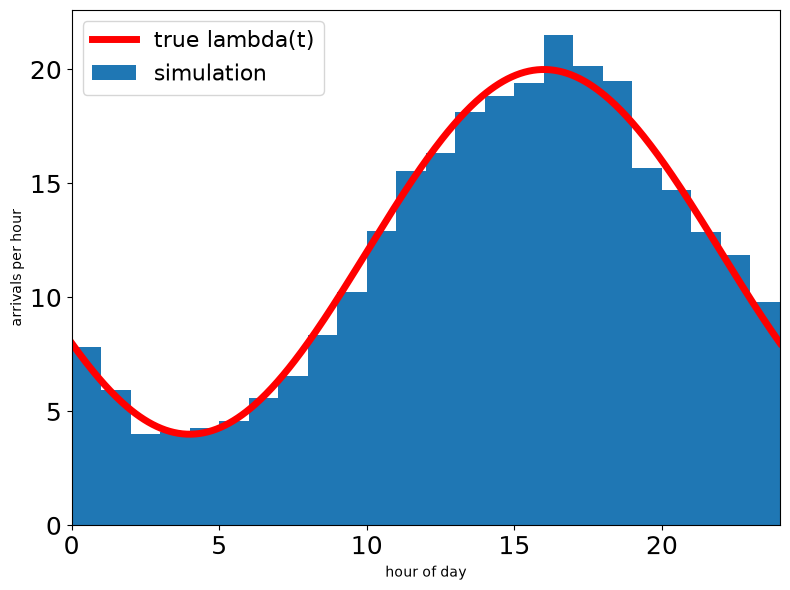

In [10]:
hour = np.floor(time % 24).astype(int)     # clock hour of each arrival
hourly_mean = np.bincount(hour, minlength=24)/ndays
 
tt = np.linspace(0, 24, 500)
plt.figure(1, figsize=(8, 6))
plt.bar(np.arange(24) + 0.5, hourly_mean, width=1, label='simulation')
plt.plot(tt, lam(tt), 'red', linewidth=5, label='true lambda(t)')
plt.xlim([0, 24])
plt.legend(fontsize=16)
plt.tick_params(labelsize=18)
plt.xlabel('hour of day')
plt.ylabel('arrivals per hour')
plt.tight_layout()

In [12]:
# arrivals from 3-4am on every day of the 30
day = np.floor(time/24).astype(int)        # day of each arrival
counts34 = np.bincount(day[hour == 3], minlength=ndays)
 
print('3-4 am: mean', np.mean(counts34), 'var', np.var(counts34),
      '  Poisson(4.091): mean = var = 4.091')
 

3-4 am: mean 4.1 var 4.29   Poisson(4.091): mean = var = 4.091


In [14]:
def negloglik(p):
    a, b, phi = p
    rate = a + b*np.cos(np.pi*(time - phi)/12)
    if np.any(rate <= 0):               # a rate must be positive
        return np.inf
    Lam = a*T + 12*b/np.pi*(np.sin(np.pi*(T - phi)/12) - np.sin(np.pi*(0 - phi)/12))
    return -(np.sum(np.log(rate)) - Lam)
 
fit = minimize(negloglik, [10, 5, 14], method='Nelder-Mead')
 
print('MLE (a, b, phi):', fit.x)
print('max log-likelihood, cosine rate:', -fit.fun)
print('max log-likelihood, constant rate n/T:', n*np.log(n/T) - n)

MLE (a, b, phi): [12.02918917  8.09549388 16.17202495]
max log-likelihood, cosine rate: 13930.21859717481
max log-likelihood, constant rate n/T: 12881.801993995694
